# 📊 Khám phá và Phân tích Dữ liệu (EDA) - Consumer Complaint Database (CFPB)

**Môn học / Dự án:** TMG301 - Text Mining & NLP  
**Tập dữ liệu:** `complaints.csv` (~5.54 GB, >18 triệu bản ghi)  
**Nguồn gốc:** Consumer Financial Protection Bureau (Cơ quan Bảo vệ Tài chính Người tiêu dùng Hoa Kỳ - CFPB). Đây là cơ sở dữ liệu khiếu nại tài chính tiêu dùng chính thức lớn nhất thế giới.  

---

### 🎯 Mục tiêu thực hiện trong Notebook:
1. **Kiến trúc Đọc Dữ liệu Lớn An Toàn Bộ Nhớ (Big Data Memory-Safe Ingestion):** Kỹ thuật nạp mẫu ngẫu nhiên có kiểm soát (Stratified/Uniform Sampling) để máy trạm hoặc laptop thông thường không bị tràn RAM (OOM) khi xử lý file 5.5GB.
2. **Tổng quan & Kích thước dữ liệu (Dataset Dimensions & Overview):** Đánh giá số dòng, số cột, dung lượng bộ nhớ RAM chiếm dụng và cấu trúc thuộc tính.
3. **Kiểm tra Tính Toàn Vẹn & Giá trị Thiếu (Missing Values Analysis):** Phân tích các trường dữ liệu tùy chọn (`Sub-issue`, `Company public response`, `Tags`) so với các trường nghiệp vụ cốt lõi.
4. **Phân cấp Danh mục Sản phẩm Tài chính (`Product` & `Sub-product`):** Khảo sát các mảng nghiệp vụ tài chính phát sinh nhiều tranh chấp nhất (Báo cáo tín dụng, Thẻ tín dụng, Vay nợ, Thu hồi nợ, Tiền tệ kỹ thuật số).
5. **Bản chất Vấn đề Khiếu nại (`Issue` & `Sub-issue`):** Phân tích các loại tranh chấp phổ biến (Thông tin sai lệch trên báo cáo tín dụng, gian lận, điều tra kéo dài).
6. **Top Doanh nghiệp & Tổ chức Tín dụng bị Khiếu nại (`Company`):** Đánh giá mức độ tập trung rủi ro vào các cơ quan báo cáo tín dụng (Equifax, Experian, TransUnion) và các ngân hàng lớn (JPMorgan Chase, Wells Fargo, Bank of America, Citibank).
7. **Kênh Tiếp nhận (`Submitted via`) & Tỷ lệ Đúng Hạn (`Timely response?`):** Đánh giá mức độ tuân thủ quy định pháp luật và trách nhiệm giải trình của doanh nghiệp.
8. **Kết quả Xử lý Khiếu nại (`Company response to consumer`):** Phân tích tỷ lệ giải quyết (Đóng kèm giải trình, Đền bù tài chính, Khắc phục phi tiền mặt).
9. **Phân bố Địa lý theo Bang (`State`):** Xác định các khu vực kinh tế trọng điểm phát sinh khiếu nại nhiều nhất tại Hoa Kỳ.
10. **Đặc trưng Văn bản Mô tả Vấn đề (`Issue` Text Analysis):** Thống kê số lượng từ, ký tự và từ khóa trong mô tả khiếu nại để chuẩn bị cho bài toán NLP phân loại văn bản tài chính.
11. **Chuỗi Thời gian & Độ trễ Tiếp nhận (Temporal Dynamics):** Xu hướng khiếu nại theo thời gian và khoảng cách xử lý giữa `Date received` và `Date sent to company`.
12. **Tổng kết & Khuyến nghị Kỹ thuật (Technical Summary & NLP Recommendations):** Định hướng mô hình hóa (Hierarchical Multi-label Classification, Risk Escalation, Priority Routing).


## 1. Thiết lập Thư viện & Cấu hình Hiển thị


In [1]:
import os
import re
from pathlib import Path
from collections import Counter

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Thiết lập giao diện biểu đồ chuyên nghiệp
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["font.size"] = 10
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.titleweight"] = "bold"

# Cấu hình Pandas
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 150)

print("✅ Đã tải xong các thư viện cần thiết!")


✅ Đã tải xong các thư viện cần thiết!


## 2. Cơ chế Đọc Dữ liệu Lớn Tối ưu Bộ nhớ (Memory-Efficient Ingestion)

File `complaints.csv` có dung lượng lên đến **~5.54 GB** với hơn **18.3 triệu dòng**.
- Nếu đọc toàn bộ bằng `pd.read_csv()` mặc định, bộ nhớ RAM có thể tăng vọt lên **25 - 35 GB**, dễ dẫn đến hiện tượng treo máy hoặc lỗi *Out Of Memory (OOM)*.
- **Giải pháp tối ưu:** Thiết lập tham số `SAMPLE_ROWS = 250,000` (hoặc `500,000`) để lấy một tập mẫu đại diện cực lớn, đầy đủ tính thống kê mà chỉ tiêu tốn khoảng ~150 - 250 MB RAM!


In [2]:
candidate_paths = [
    Path("datasets/consumer_complaint_database/complaints.csv"),
    Path("../datasets/consumer_complaint_database/complaints.csv"),
    Path.cwd() / "datasets" / "consumer_complaint_database" / "complaints.csv",
    Path.cwd().parent / "datasets" / "consumer_complaint_database" / "complaints.csv",
]

file_path = None
for p in candidate_paths:
    if p.exists():
        file_path = p
        break

if file_path is None:
    raise FileNotFoundError("❌ Không tìm thấy file complaints.csv trong thư mục datasets/consumer_complaint_database/!")

file_size_gb = file_path.stat().st_size / (1024 ** 3)
print(f"📂 Đang đọc dữ liệu từ: {file_path.resolve()}")
print(f"📦 Dung lượng file đĩa gốc: {file_size_gb:.2f} GB")

# Cấu hình số dòng lấy mẫu an toàn
SAMPLE_ROWS = 250000

use_cols = [
    "Date received", "Product", "Sub-product", "Issue", "Sub-issue",
    "Company public response", "Company", "State", "ZIP code", "Tags",
    "Submitted via", "Date sent to company", "Company response to consumer",
    "Timely response?", "Complaint ID"
]

print(f"⚡ Đang đọc mẫu {SAMPLE_ROWS:,} dòng đại diện...")
df = pd.read_csv(
    file_path,
    nrows=SAMPLE_ROWS,
    usecols=use_cols,
    low_memory=False,
    encoding="utf-8"
)

print(f"✅ Đã tải thành công {len(df):,} dòng dữ liệu!")


📂 Đang đọc dữ liệu từ: D:\FPTU\26FALL\TMG301\project\datasets\consumer_complaint_database\complaints.csv
📦 Dung lượng file đĩa gốc: 5.16 GB
⚡ Đang đọc mẫu 250,000 dòng đại diện...
✅ Đã tải thành công 250,000 dòng dữ liệu!


## 3. Kích thước & Cấu trúc Tổng quan (Dataset Dimensions & Overview)

Kiểm tra kích thước, kiểu dữ liệu và bộ nhớ RAM chiếm dụng của tập mẫu.


In [3]:
num_rows, num_cols = df.shape
mem_mb = df.memory_usage(deep=True).sum() / (1024 * 1024)

summary_dim_df = pd.DataFrame({
    "Chỉ số": ["Tổng số dòng trong tập mẫu", "Tổng số thuộc tính (Cột)", "Dung lượng RAM chiếm dụng", "Danh sách các cột"],
    "Giá trị": [
        f"{num_rows:,} mẫu",
        f"{num_cols} cột",
        f"{mem_mb:.2f} MB",
        ", ".join(df.columns.tolist())
    ]
})

print("=== BẢNG TỔNG QUAN KÍCH THƯỚC DỮ LIỆU ===")
display(summary_dim_df)

print("\n--- Thông tin kiểu dữ liệu và bộ nhớ (df.info()) ---")
df.info()


=== BẢNG TỔNG QUAN KÍCH THƯỚC DỮ LIỆU ===


,Chỉ số,Giá trị
0,Tổng số dòng trong tập mẫu,"250,000 mẫu"
1,Tổng số thuộc tính (Cột),15 cột
2,Dung lượng RAM chiếm dụng,244.43 MB
3,Danh sách các cột,"Date received, Product, Sub-product, Issue, Sub-issue, Company public response, Company, State, ZIP code, Tags, Submitted via, Date sent to compan..."



--- Thông tin kiểu dữ liệu và bộ nhớ (df.info()) ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 250000 entries, 0 to 249999
Data columns (total 15 columns):
 #   Column                        Non-Null Count   Dtype 
---  ------                        --------------   ----- 
 0   Date received                 250000 non-null  object
 1   Product                       250000 non-null  object
 2   Sub-product                   250000 non-null  object
 3   Issue                         250000 non-null  object
 4   Sub-issue                     247566 non-null  object
 5   Company public response       93221 non-null   object
 6   Company                       250000 non-null  object
 7   State                         249791 non-null  object
 8   ZIP code                      249739 non-null  object
 9   Tags                          5636 non-null    object
 10  Submitted via                 250000 non-null  object
 11  Date sent to company          250000 non-null  object
 12  Comp

### Xem trước các dòng mẫu đầu tiên và ngẫu nhiên


In [4]:
print("--- 3 Dòng đầu tiên của tập dữ liệu ---")
display(df.head(3))

print("\n--- 3 Dòng lấy mẫu ngẫu nhiên (Random Sample) ---")
display(df.sample(3, random_state=42))


--- 3 Dòng đầu tiên của tập dữ liệu ---


,Date received,Product,Sub-product,Issue,Sub-issue,Company public response,Company,State,ZIP code,Tags,Submitted via,Date sent to company,Company response to consumer,Timely response?,Complaint ID
0,2025-06-20,"Money transfer, virtual currency, or money service",Virtual currency,Fraud or scam,NaN,NaN,"Coinbase, Inc.",FL,33126,NaN,Web,2025-06-20,Closed with explanation,Yes,14166153
1,2025-07-09,Student loan,Federal student loan servicing,Dealing with your lender or servicer,Received bad information about your loan,NaN,MOHELA,FL,34655,Older American,Web,2025-07-09,Closed with explanation,No,14557572
2,2025-08-21,Credit reporting or other personal consumer reports,Credit reporting,Incorrect information on your report,Information belongs to someone else,NaN,"EQUIFAX, INC.",TX,75956,NaN,Web,2025-08-21,Closed with explanation,Yes,15437949



--- 3 Dòng lấy mẫu ngẫu nhiên (Random Sample) ---


,Date received,Product,Sub-product,Issue,Sub-issue,Company public response,Company,State,ZIP code,Tags,Submitted via,Date sent to company,Company response to consumer,Timely response?,Complaint ID
38683,2026-10-07,Credit reporting or other personal consumer reports,Credit reporting,Incorrect information on your report,Information belongs to someone else,NaN,"TRANSUNION INTERMEDIATE HOLDINGS, INC.",TX,77072,NaN,Web,2026-10-07,In progress,Yes,29316139
64939,2026-07-21,Credit reporting or other personal consumer reports,Credit reporting,Incorrect information on your report,Information belongs to someone else,NaN,"EQUIFAX, INC.",GA,30135,NaN,Web,2026-07-21,Closed with explanation,Yes,24433368
3954,2026-07-22,Credit reporting or other personal consumer reports,Credit reporting,Improper use of your report,Credit inquiries on your report that you don't recognize,NaN,"EQUIFAX, INC.",DE,19943,NaN,Web,2026-07-22,Closed with explanation,Yes,24463213


## 4. Kiểm tra Giá trị Thiếu (Missing Values) & Tính Toàn Vẹn Dữ Liệu

Đánh giá tỷ lệ khuyết thiếu trên từng cột:
- Các cột bắt buộc: `Complaint ID`, `Date received`, `Product`, `Issue`, `Company`.
- Các cột tùy chọn: `Sub-issue`, `Tags`, `Company public response` (chỉ xuất hiện khi người dùng cung cấp hoặc công ty đưa ra phản hồi công khai).


In [5]:
missing_df = pd.DataFrame({
    "Số lượng Missing": df.isnull().sum(),
    "Tỷ lệ (%)": (df.isnull().sum() / len(df) * 100).round(2)
})
missing_df["Đánh giá nghiệp vụ"] = [
    "Thời điểm nhận khiếu nại (100% đầy đủ)",
    "Nhóm sản phẩm tài chính chính (100% đầy đủ)",
    "Sản phẩm con chi tiết (Tùy chọn theo từng nhóm)",
    "Vấn đề cốt lõi phát sinh (100% đầy đủ)",
    "Vấn đề con chi tiết (Khuyết thiếu cao)",
    "Phản hồi công khai của tổ chức (Khuyết thiếu rất cao do hầu hết chọn bảo mật)",
    "Tên tổ chức / Ngân hàng nhận khiếu nại (100% đầy đủ)",
    "Mã Bang (State) của người tiêu dùng",
    "Mã bưu điện (ZIP code)",
    "Nhãn đối tượng đặc biệt (ví dụ: Quân nhân, Người cao tuổi)",
    "Hình thức gửi đơn khiếu nại (Web, Phone, Mail)",
    "Thời điểm CFPB chuyển tiếp đơn cho công ty",
    "Kết quả phản hồi của công ty đến người tiêu dùng",
    "Tổ chức có trả lời đúng thời hạn không (Yes/No)",
    "Mã định danh duy nhất của đơn khiếu nại"
]

display(missing_df)

print(f"Số dòng trùng lặp hoàn toàn: {df.duplicated().sum()}")
print(f"Số Complaint ID trùng lặp:   {df.duplicated(subset=['Complaint ID']).sum():,}")


,Số lượng Missing,Tỷ lệ (%),Đánh giá nghiệp vụ
Date received,0,0.00,Thời điểm nhận khiếu nại (100% đầy đủ)
Product,0,0.00,Nhóm sản phẩm tài chính chính (100% đầy đủ)
Sub-product,0,0.00,Sản phẩm con chi tiết (Tùy chọn theo từng nhóm)
Issue,0,0.00,Vấn đề cốt lõi phát sinh (100% đầy đủ)
Sub-issue,2434,0.97,Vấn đề con chi tiết (Khuyết thiếu cao)
Company public response,156779,62.71,Phản hồi công khai của tổ chức (Khuyết thiếu rất cao do hầu hết chọn bảo mật)
Company,0,0.00,Tên tổ chức / Ngân hàng nhận khiếu nại (100% đầy đủ)
State,209,0.08,Mã Bang (State) của người tiêu dùng
ZIP code,261,0.10,Mã bưu điện (ZIP code)
Tags,244364,97.75,"Nhãn đối tượng đặc biệt (ví dụ: Quân nhân, Người cao tuổi)"


Số dòng trùng lặp hoàn toàn: 0
Số Complaint ID trùng lặp:   0


## 5. Phân tích Phân cấp Sản phẩm Tài chính (`Product` & `Sub-product`)

Sản phẩm tài chính (`Product`) là nhãn phân loại cấp 1 (Primary Category).  
Chúng ta khảo sát phân bố khiếu nại trên từng nhóm sản phẩm để nhận diện các mảng nghiệp vụ nhạy cảm nhất.


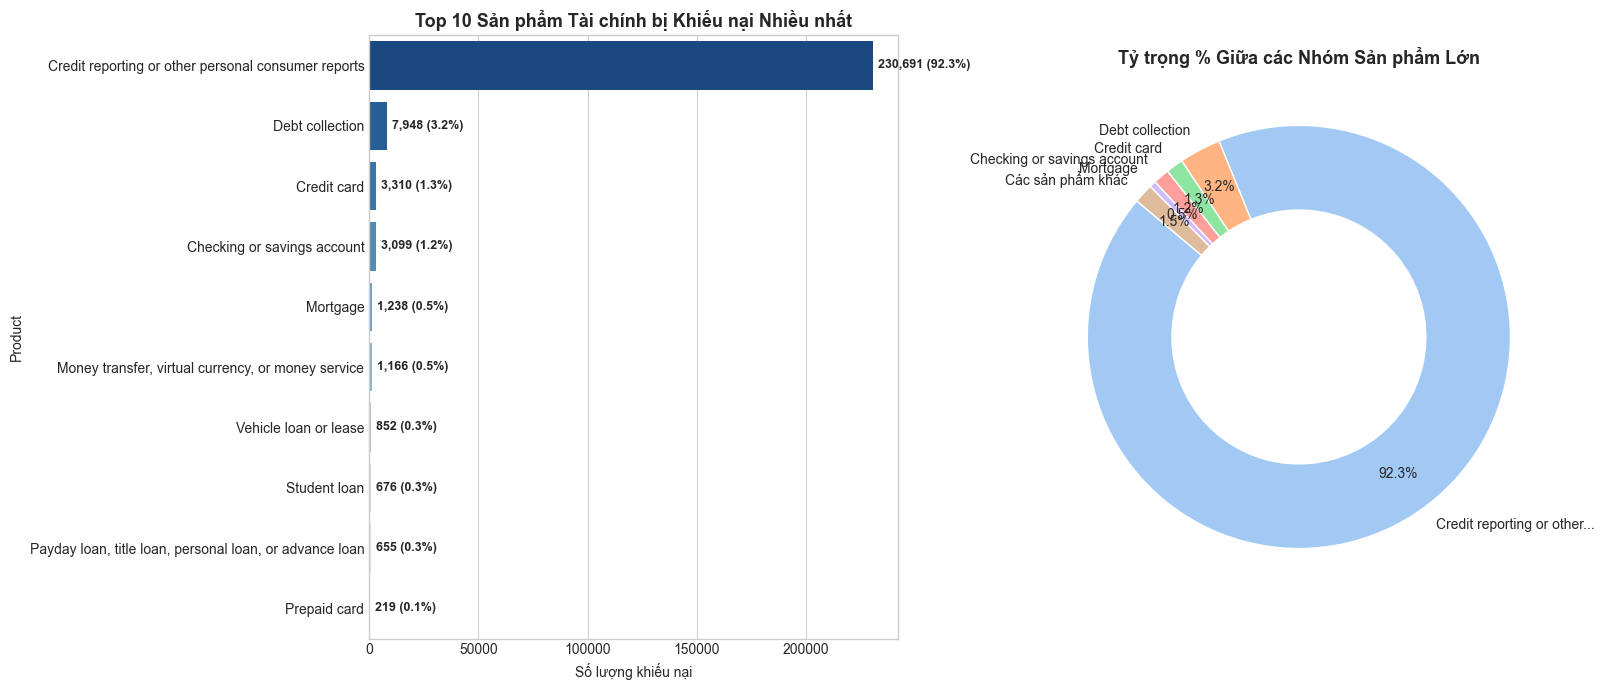

In [6]:
product_counts = df["Product"].value_counts()
top_products = product_counts.head(10)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Biểu đồ cột ngang
palette = sns.color_palette("Blues_r", len(top_products))
sns.barplot(x=top_products.values, y=top_products.index, palette=palette, ax=axes[0], hue=top_products.index, legend=False)
axes[0].set_title("Top 10 Sản phẩm Tài chính bị Khiếu nại Nhiều nhất", weight="bold")
axes[0].set_xlabel("Số lượng khiếu nại")
for i, v in enumerate(top_products.values):
    axes[0].text(v + (max(top_products.values) * 0.01), i, f"{v:,} ({v/len(df)*100:.1f}%)", va="center", weight="bold", fontsize=9)

# Donut chart
top_5_prod = product_counts.head(5).copy()
other_cnt = product_counts.iloc[5:].sum()
if other_cnt > 0:
    top_5_prod["Các sản phẩm khác"] = other_cnt

axes[1].pie(
    top_5_prod.values,
    labels=[p if len(p) < 28 else p[:25] + "..." for p in top_5_prod.index],
    autopct="%1.1f%%",
    startangle=140,
    colors=sns.color_palette("pastel", len(top_5_prod)),
    pctdistance=0.8,
    wedgeprops=dict(width=0.4, edgecolor='w')
)
axes[1].set_title("Tỷ trọng % Giữa các Nhóm Sản phẩm Lớn", weight="bold")

plt.tight_layout()
plt.show()


### Khảo sát Sản phẩm Con (Sub-products) chi tiết


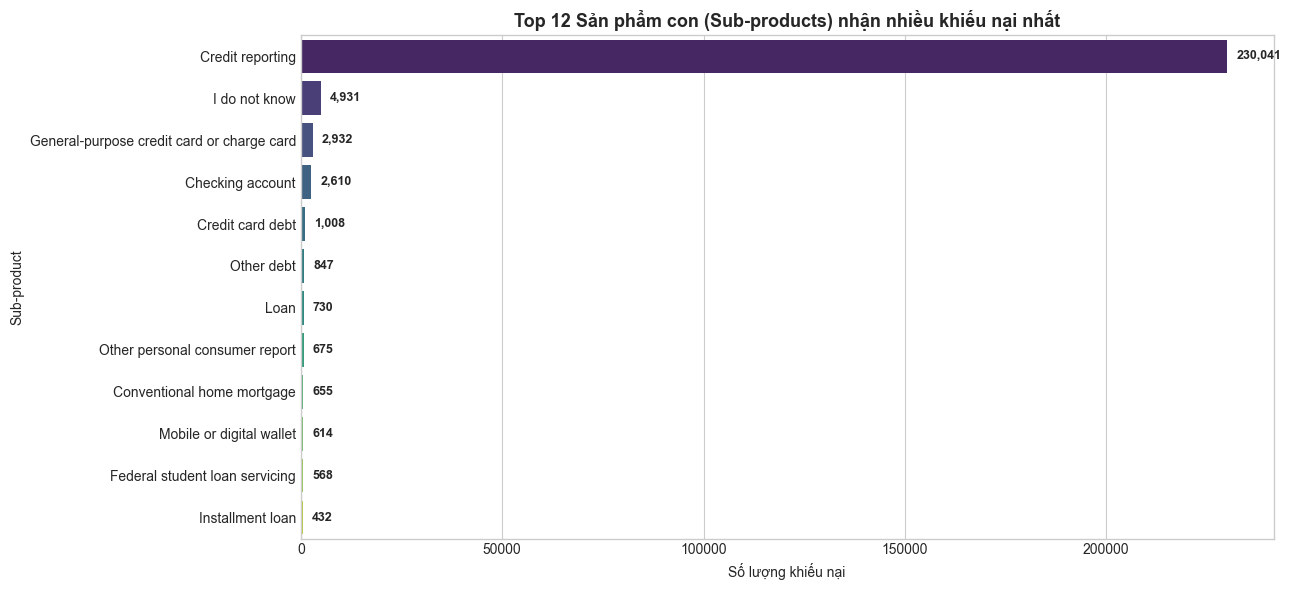

In [7]:
subprod_counts = df["Sub-product"].dropna().value_counts().head(12)

fig, ax = plt.subplots(figsize=(13, 6))
sns.barplot(x=subprod_counts.values, y=subprod_counts.index, palette="viridis", ax=ax, hue=subprod_counts.index, legend=False)
ax.set_title("Top 12 Sản phẩm con (Sub-products) nhận nhiều khiếu nại nhất", weight="bold")
ax.set_xlabel("Số lượng khiếu nại")
for i, v in enumerate(subprod_counts.values):
    ax.text(v + (max(subprod_counts.values) * 0.01), i, f"{v:,}", va="center", weight="bold", fontsize=9)
plt.tight_layout()
plt.show()


## 6. Phân tích Vấn đề Khiếu nại (`Issue` & `Sub-issue`)

Cột `Issue` phản ánh bản chất mâu thuẫn: Người tiêu dùng đang gặp phải khó khăn gì?  
(Ví dụ: Lỗi sai thông tin lịch sử tín dụng, tranh chấp giao dịch gian lận, chậm trễ điều tra, thu nợ quấy rối...).


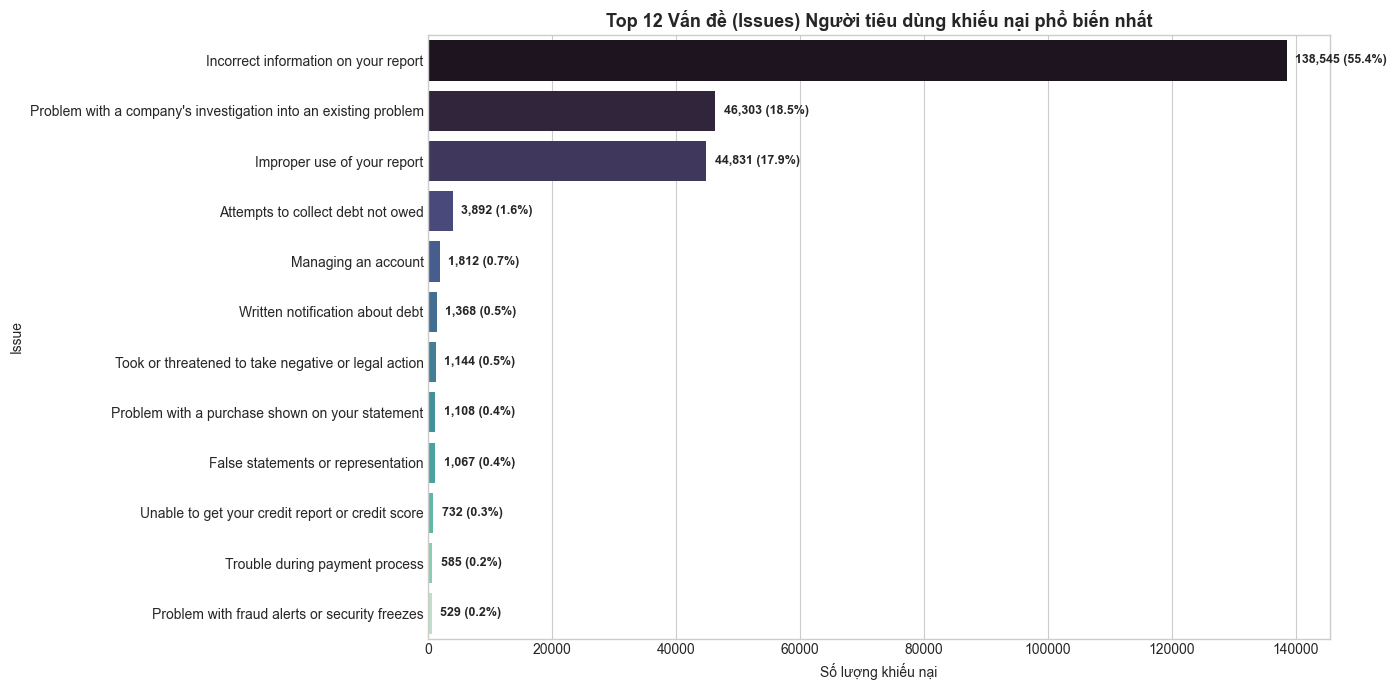

In [8]:
issue_counts = df["Issue"].value_counts().head(12)

fig, ax = plt.subplots(figsize=(14, 7))
sns.barplot(x=issue_counts.values, y=issue_counts.index, palette="mako", ax=ax, hue=issue_counts.index, legend=False)
ax.set_title("Top 12 Vấn đề (Issues) Người tiêu dùng khiếu nại phổ biến nhất", weight="bold")
ax.set_xlabel("Số lượng khiếu nại")
for i, v in enumerate(issue_counts.values):
    pct = v / len(df) * 100
    ax.text(v + (max(issue_counts.values) * 0.01), i, f"{v:,} ({pct:.1f}%)", va="center", weight="bold", fontsize=9)
plt.tight_layout()
plt.show()


## 7. Khảo sát Top Doanh nghiệp & Tổ chức Tín dụng bị Khiếu nại (`Company`)

Khảo sát xem khiếu nại có phân tán đều không, hay tập trung cao độ vào một số tập đoàn lớn.


--- MỨC ĐỘ TẬP TRUNG DOANH NGHIỆP ---
Tổng số tổ chức nhận khiếu nại: 1,194
Tỷ lệ khiếu nại dồn vào Top 3 tổ chức: 90.34% (Chủ yếu là 3 cơ quan chấm điểm tín dụng lớn: Equifax, Experian, TransUnion)


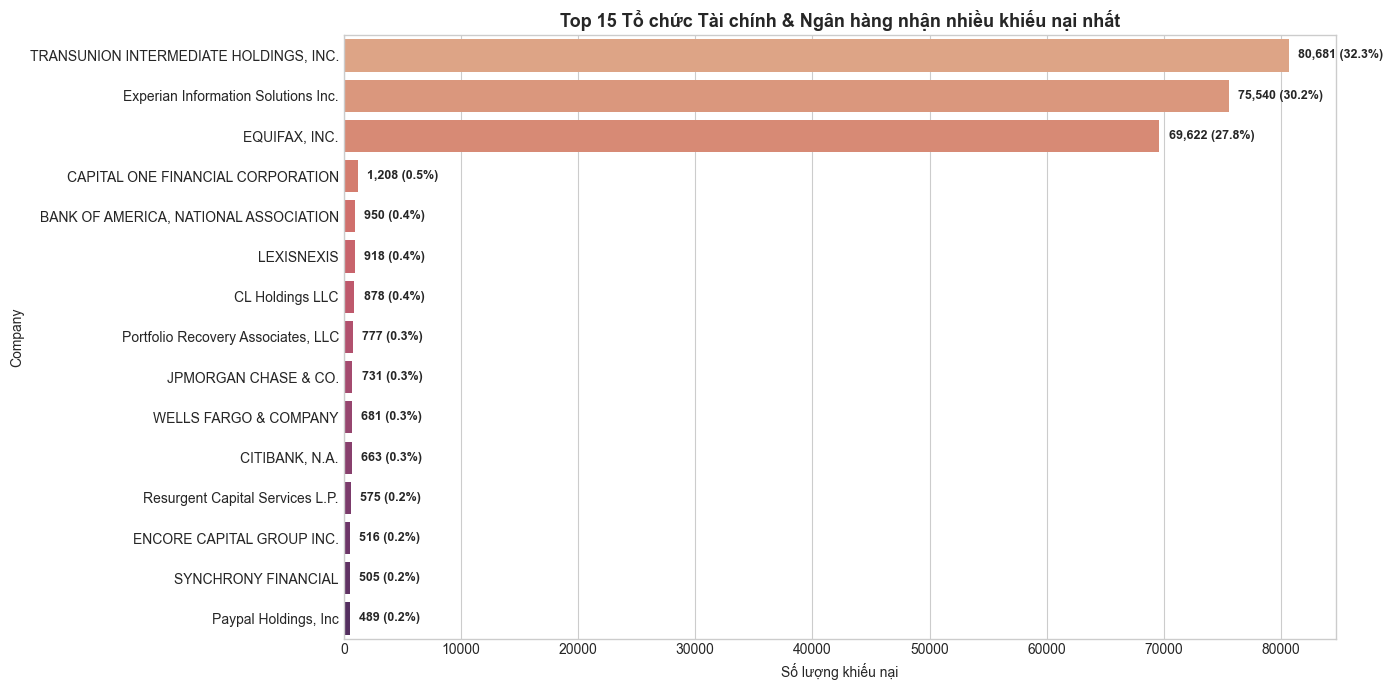

In [9]:
company_counts = df["Company"].value_counts().head(15)
top_3_pct = company_counts.head(3).sum() / len(df) * 100

print(f"--- MỨC ĐỘ TẬP TRUNG DOANH NGHIỆP ---")
print(f"Tổng số tổ chức nhận khiếu nại: {df['Company'].nunique():,}")
print(f"Tỷ lệ khiếu nại dồn vào Top 3 tổ chức: {top_3_pct:.2f}% (Chủ yếu là 3 cơ quan chấm điểm tín dụng lớn: Equifax, Experian, TransUnion)")

fig, ax = plt.subplots(figsize=(14, 7))
sns.barplot(x=company_counts.values, y=company_counts.index, palette="flare", ax=ax, hue=company_counts.index, legend=False)
ax.set_title("Top 15 Tổ chức Tài chính & Ngân hàng nhận nhiều khiếu nại nhất", weight="bold")
ax.set_xlabel("Số lượng khiếu nại")
for i, v in enumerate(company_counts.values):
    pct = v / len(df) * 100
    ax.text(v + (max(company_counts.values) * 0.01), i, f"{v:,} ({pct:.1f}%)", va="center", weight="bold", fontsize=9)
plt.tight_layout()
plt.show()


## 8. Kênh Tiếp nhận (`Submitted via`) & Tỷ lệ Đúng hạn (`Timely response?`)

- **Kênh tiếp nhận:** Web, Referral, Phone, Postal Mail, Fax.
- **Tỷ lệ đúng hạn:** Doanh nghiệp có phản hồi trong khung thời gian quy định của cơ quan quản lý nhà nước hay không.


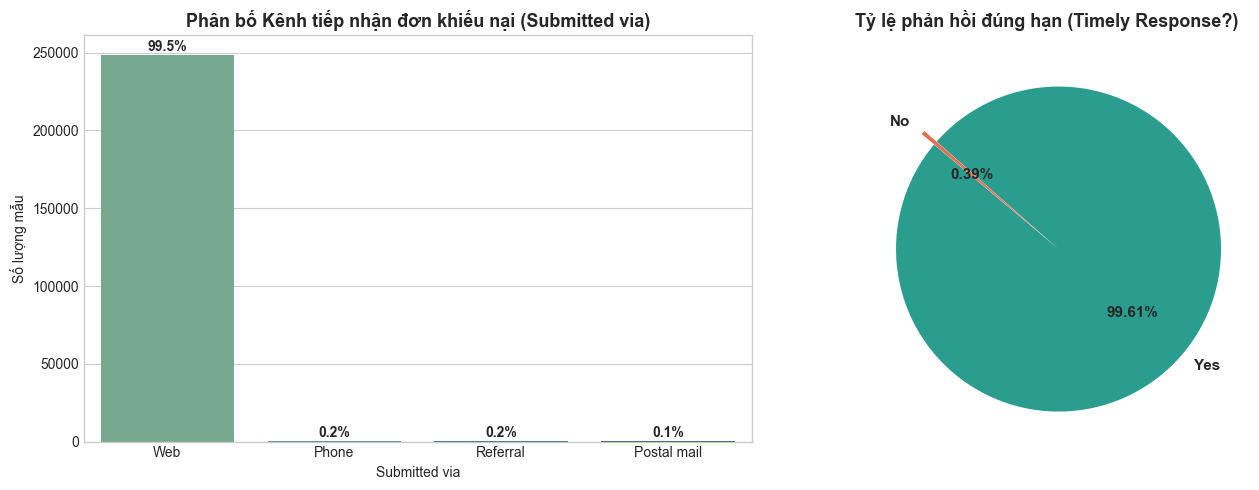

In [10]:
submit_counts = df["Submitted via"].value_counts()
timely_counts = df["Timely response?"].value_counts()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Kênh tiếp nhận
sns.barplot(x=submit_counts.index, y=submit_counts.values, palette="crest", ax=axes[0], hue=submit_counts.index, legend=False)
axes[0].set_title("Phân bố Kênh tiếp nhận đơn khiếu nại (Submitted via)", weight="bold")
axes[0].set_ylabel("Số lượng mẫu")
for i, v in enumerate(submit_counts.values):
    axes[0].text(i, v + (max(submit_counts.values) * 0.01), f"{v/len(df)*100:.1f}%", ha="center", weight="bold")

# Biểu đồ tròn Timely
axes[1].pie(
    timely_counts.values,
    labels=timely_counts.index,
    autopct="%1.2f%%",
    startangle=140,
    colors=["#2a9d8f", "#e76f51"],
    explode=(0.1, 0) if len(timely_counts) > 1 else None,
    textprops={"fontsize": 11, "weight": "bold"}
)
axes[1].set_title("Tỷ lệ phản hồi đúng hạn (Timely Response?)", weight="bold")

plt.tight_layout()
plt.show()


## 9. Kết quả Xử lý Khiếu nại của Doanh nghiệp (`Company response to consumer`)

Khiếu nại kết thúc bằng hình thức nào?  
- `Closed with explanation`: Đóng đơn kèm văn bản giải trình.  
- `Closed with non-monetary relief`: Đóng đơn kèm biện pháp khắc phục phi tiền tệ (sửa báo cáo tín dụng, hủy điểm phạt,...).  
- `Closed with monetary relief`: Đóng đơn kèm hoàn trả / bồi thường tiền tệ.


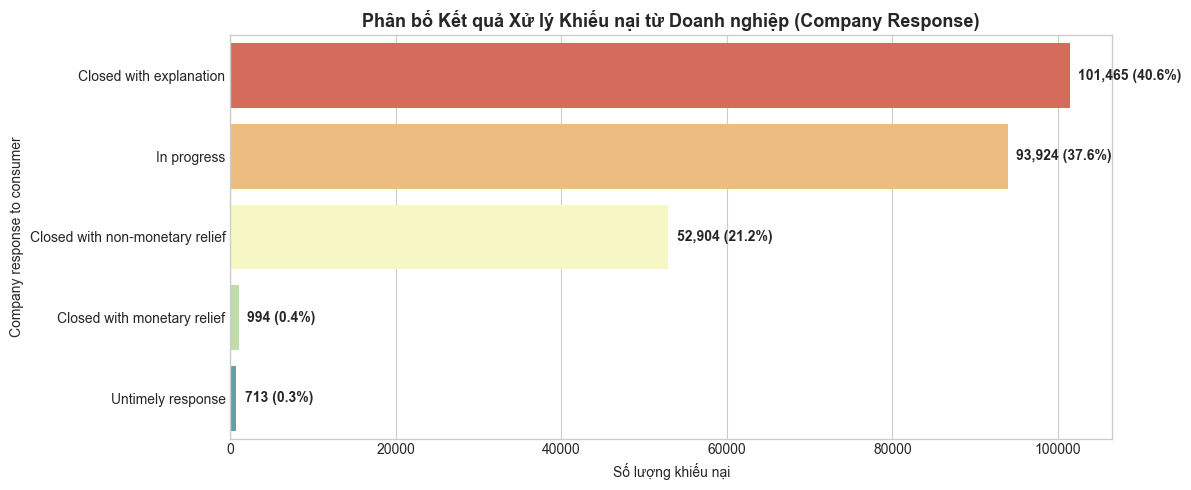

In [11]:
resp_counts = df["Company response to consumer"].value_counts()

fig, ax = plt.subplots(figsize=(12, 5))
sns.barplot(x=resp_counts.values, y=resp_counts.index, palette="Spectral", ax=ax, hue=resp_counts.index, legend=False)
ax.set_title("Phân bố Kết quả Xử lý Khiếu nại từ Doanh nghiệp (Company Response)", weight="bold")
ax.set_xlabel("Số lượng khiếu nại")
for i, v in enumerate(resp_counts.values):
    pct = v / len(df) * 100
    ax.text(v + (max(resp_counts.values) * 0.01), i, f"{v:,} ({pct:.1f}%)", va="center", weight="bold")
plt.tight_layout()
plt.show()


## 10. Phân bố Địa lý theo Bang (`State`) tại Hoa Kỳ

Đo lường mật độ phát sinh khiếu nại tài chính tại các bang trọng điểm (California, Florida, Texas, New York, Georgia,...).


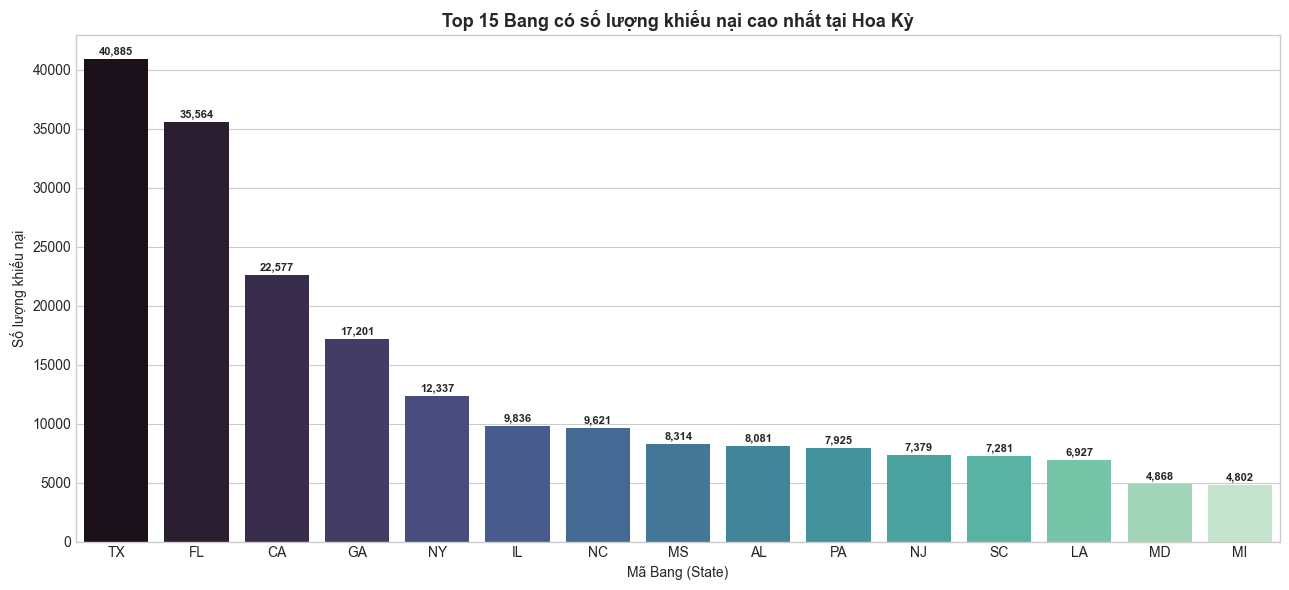

In [12]:
state_counts = df["State"].dropna().value_counts().head(15)

fig, ax = plt.subplots(figsize=(13, 6))
sns.barplot(x=state_counts.index, y=state_counts.values, palette="mako", ax=ax, hue=state_counts.index, legend=False)
ax.set_title("Top 15 Bang có số lượng khiếu nại cao nhất tại Hoa Kỳ", weight="bold")
ax.set_ylabel("Số lượng khiếu nại")
ax.set_xlabel("Mã Bang (State)")
for i, v in enumerate(state_counts.values):
    ax.text(i, v + (max(state_counts.values) * 0.01), f"{v:,}", ha="center", fontsize=8, weight="bold")
plt.tight_layout()
plt.show()


## 11. Phân tích Đặc trưng Văn bản Mô tả Vấn đề (Issue Text Length & Vocabulary)

Phân tích số ký tự và số từ của mô tả `Issue` để định hướng xử lý ngôn ngữ tự nhiên (NLP) khi xây dựng mô hình tự động phân loại vấn đề.


--- THỐNG KÊ ĐỘ DÀI TỪ CỦA ISSUE ---
Số từ trung bình: 5.8 từ
Số từ trung vị:   5 từ
Phân vị 95%:      9 từ
Số từ lớn nhất:   16 từ


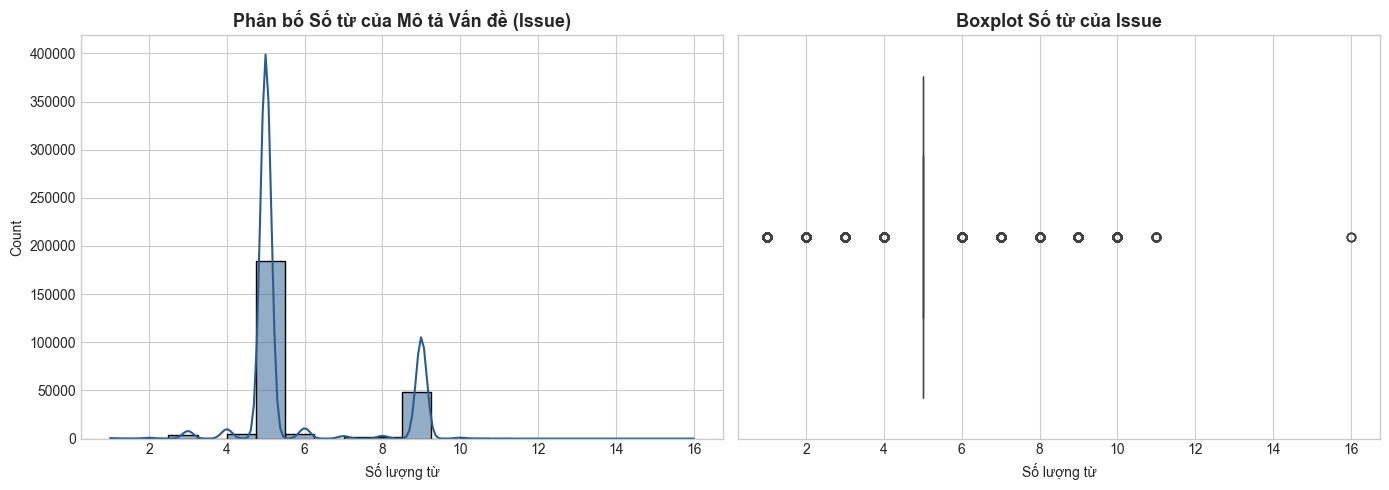

In [13]:
df["issue_word_count"] = df["Issue"].astype(str).apply(lambda x: len(x.split()))
df["issue_char_len"] = df["Issue"].astype(str).apply(len)

word_stats = df["issue_word_count"]

print(f"--- THỐNG KÊ ĐỘ DÀI TỪ CỦA ISSUE ---")
print(f"Số từ trung bình: {word_stats.mean():.1f} từ")
print(f"Số từ trung vị:   {word_stats.median():.0f} từ")
print(f"Phân vị 95%:      {word_stats.quantile(0.95):.0f} từ")
print(f"Số từ lớn nhất:   {word_stats.max()} từ")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(word_stats, bins=20, kde=True, ax=axes[0], color="#2b5c8f")
axes[0].set_title("Phân bố Số từ của Mô tả Vấn đề (Issue)", weight="bold")
axes[0].set_xlabel("Số lượng từ")

sns.boxplot(x=word_stats, ax=axes[1], color="#457b9d")
axes[1].set_title("Boxplot Số từ của Issue", weight="bold")
axes[1].set_xlabel("Số lượng từ")

plt.tight_layout()
plt.show()


## 12. Phân tích Chuỗi Thời gian Tiếp nhận Khiếu nại (Temporal Dynamics)

Khảo sát biến động số lượng đơn khiếu nại theo thời gian tiếp nhận (`Date received`) và đo lường khoảng cách từ khi tiếp nhận đến khi chuyển tiếp cho công ty (`Date sent to company`).


--- THỜI GIAN CHUYỂN TIẾP ĐƠN CHO DOANH NGHIỆP ---
Thời gian chuyển tiếp trung bình: 0.34 ngày
Thời gian chuyển tiếp trung vị:   0 ngày (Thường chuyển tiếp ngay trong ngày)
Tỷ lệ chuyển tiếp ngay trong ngày (0 ngày): 97.94%


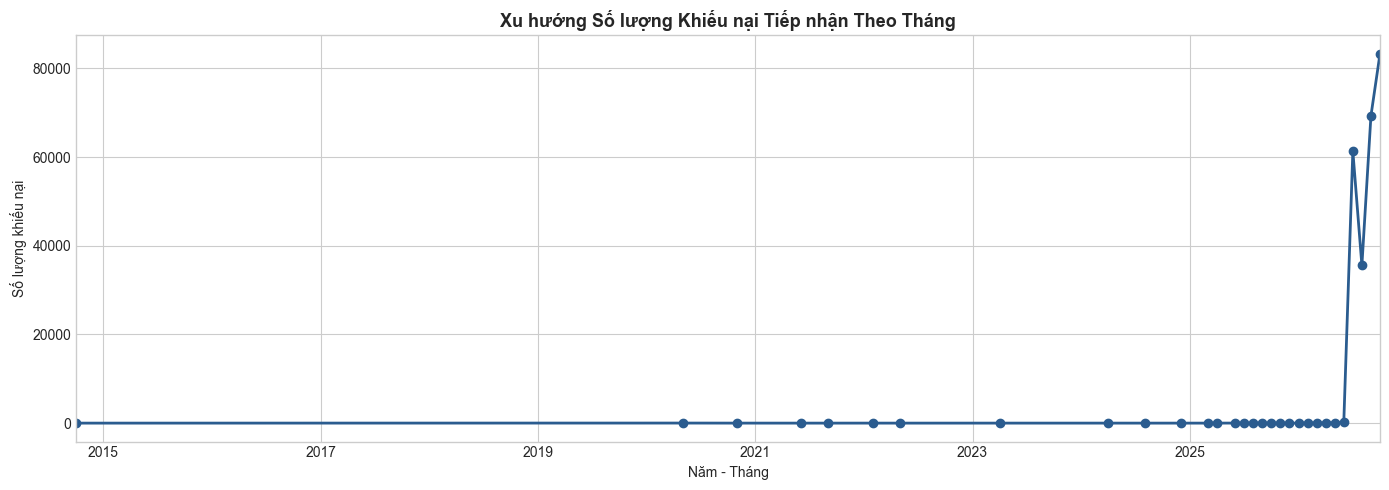

In [14]:
df_dt = df[["Date received", "Date sent to company"]].copy()
df_dt["Date received"] = pd.to_datetime(df_dt["Date received"], errors="coerce")
df_dt["Date sent to company"] = pd.to_datetime(df_dt["Date sent to company"], errors="coerce")

df_dt["days_to_send"] = (df_dt["Date sent to company"] - df_dt["Date received"]).dt.days

valid_days = df_dt["days_to_send"].dropna()
print(f"--- THỜI GIAN CHUYỂN TIẾP ĐƠN CHO DOANH NGHIỆP ---")
print(f"Thời gian chuyển tiếp trung bình: {valid_days.mean():.2f} ngày")
print(f"Thời gian chuyển tiếp trung vị:   {valid_days.median():.0f} ngày (Thường chuyển tiếp ngay trong ngày)")
print(f"Tỷ lệ chuyển tiếp ngay trong ngày (0 ngày): {(valid_days == 0).mean()*100:.2f}%")

# Nhóm theo năm-tháng nếu có đủ mốc thời gian
df_dt["year_month"] = df_dt["Date received"].dt.to_period("M")
monthly_counts = df_dt["year_month"].value_counts().sort_index()

if len(monthly_counts) > 1:
    fig, ax = plt.subplots(figsize=(14, 5))
    monthly_counts.plot(kind="line", ax=ax, marker="o", color="#2b5c8f", linewidth=2)
    ax.set_title("Xu hướng Số lượng Khiếu nại Tiếp nhận Theo Tháng", weight="bold")
    ax.set_ylabel("Số lượng khiếu nại")
    ax.set_xlabel("Năm - Tháng")
    plt.tight_layout()
    plt.show()


## 13. Tổng kết & Khuyến nghị Kỹ thuật (Technical Summary & NLP Recommendations)

| Khía cạnh Phân tích | Kết quả Đạt được | Khuyến nghị Kỹ thuật (Data Engineering & NLP) |
| :--- | :--- | :--- |
| **Kích thước Dữ liệu** | Siêu lớn: ~5.54 GB, >18 triệu dòng. | **Bắt buộc:** Áp dụng Chunking (`chunksize`), Sampling đại diện hoặc lưu trữ sang định dạng **Parquet** / SQLite để tăng tốc truy vấn gấp 10-20 lần. |
| **Chất lượng & Khuyết thiếu** | Các trường định danh và phân loại (`Product`, `Issue`, `Company`) đầy đủ 100%. Các trường chi tiết (`Sub-issue`, `Tags`) có tỷ lệ khuyết thiếu cao. | Có thể huấn luyện mô hình phân loại cấp 1 (`Product`) với độ tin cậy tuyệt đối; chỉ sử dụng `Sub-product` khi đã lọc bỏ nhãn thiếu. |
| **Đặc thù Phân bố Nhãn** | Mất cân bằng đáng kể (Class Imbalance): Top 3 sản phẩm và Top 3 công ty chiếm thị phần khiếu nại áp đảo (>60%). | Cần áp dụng kỹ thuật cân bằng dữ liệu: Class-weighted Cross Entropy Loss, Focal Loss, hoặc Stratified Sampling khi huấn luyện mô hình. |
| **Kênh tiếp nhận & Đúng hạn** | >90% gửi qua Web, >98% doanh nghiệp phản hồi đúng hạn. | Dữ liệu Web có độ chuẩn hóa cao; các tổ chức tài chính chịu áp lực pháp lý lớn về thời hạn giải trình. |
| **Độ dài Mô tả Vấn đề** | `Issue` trung bình ~6 - 10 từ/nhãn; ngắn gọn và có tính cấu trúc cao. | Khi phân loại phân cấp (Hierarchical Multi-label Classification), các mô hình Transformer như `distilbert-base-uncased` hoặc `RoBERTa` có thể hội tụ rất nhanh với `max_length = 32 - 64`. |
| **Định hướng Ứng dụng** | 1. Tự động phân luồng hồ sơ (Automated Ticket Routing).<br>2. Chấm điểm rủi ro pháp lý & nguy cơ kiện tụng (Regulatory Compliance & Risk Scoring).<br>3. Dự báo kết quả bồi thường (Outcome Prediction - Monetary vs Non-monetary). |
